# Agentic AI-SOC for EV Charging: Dataset Findings (Review Notebook)
**CICEVSE2024** · Aadhithya VM, Dharini Manimaran, Divyadharshini R · Guide: Dr. Sundharakumar

This notebook only *reads the saved results* of the full experiment run (no retraining), so it runs in seconds and every number here is a measured output.

**Contents:** 1 Dataset · 2 Cleaning · 3 Evaluation design · 4 Headline results · 5 Model comparison · 6 Confusion matrices · 7 Generalisation across recordings · 8 Network · 9 Anomaly detection · 10 Feature importance · 11 Findings

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.image as mpimg
from pathlib import Path
from IPython.display import display
R = Path("preliminary_results")          # folder with the saved results
BLUE, ORANGE, GREY = "#335295", "#B7791F", "#9BB0DB"
pd.set_option("display.max_columns", 30, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
M = pd.read_csv(R/"metrics_summary.csv").drop_duplicates(["experiment","model"], keep="last").set_index(["experiment","model"])
def m(exp, model="RandomForest", col="macro_F1"):
    try: return float(M.loc[(exp, model), col])
    except KeyError: return np.nan
print("Experiments loaded:", M.index.get_level_values(0).nunique(), "| rows:", len(M))

Experiments loaded: 50 | rows: 110


## 1. Dataset overview
Three evidence sources. Power and host data come from **EVSE-B**; network flows from **EVSE-A and EVSE-B**.

source,rows,benign,attack,attack_%
Power (EVSE-B),"115,298","14,363","100,935",87.500000
Host (EVSE-B),"8,468","2,302","6,166",72.800000
Network EVSE-A (Combined file),"547,854",82,"547,772",100.000000
Network EVSE-B (Combined file),"2,196,846",0,"2,196,846",100.000000


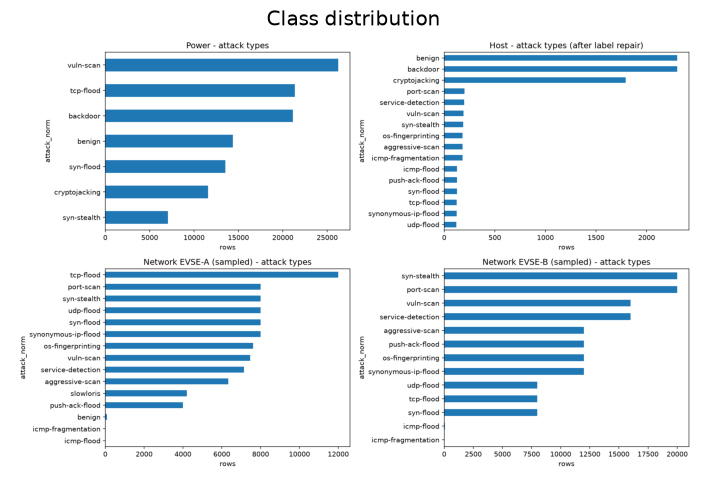

In [2]:
inv = pd.read_csv(R/"dataset_inventory.csv"); inv["attack_%"] = (100*inv["attack"]/inv["rows"]).round(1)
display(inv.style.format({"rows":"{:,}","benign":"{:,}","attack":"{:,}"}).hide(axis="index"))
plt.figure(figsize=(9,5.2)); plt.imshow(mpimg.imread(R/"class_distribution.png")); plt.axis("off"); plt.title("Class distribution"); plt.show()

**Takeaway:** the data is strongly imbalanced (network benign is almost absent), so accuracy alone is misleading. We report macro-F1, per-class recall and a majority-class baseline for every experiment.

## 2. Data cleaning decisions

In [3]:
for s in pd.read_csv(R/"cleaning_log.csv").iloc[:,0].drop_duplicates(): print("•", s, "\n")

• Power: 115,298 rows kept. 1,100 exact duplicates NOT dropped: timestamps are minute-level with up to 59 readings/minute, so repeats are plausible repeated sensor readings; blocked split prevents them leaking across train/test. 

• Host: 8,474 raw rows -> 8,468 usable; dropped 6 blank/header/stray rows. 

• Host: dropped 622 constant/empty counter columns; 283 usable features remain for 8,468 rows (high feature:row ratio -> overfitting risk). 

• Network EVSE-A: read 547,854 rows, sampled 88,858 (62 candidate features). 

• Network EVSE-B: read 2,196,846 rows, sampled 144,072 (62 candidate features). 

• EVSE-A: 82 benign flows loaded from dedicated benign CSVs (Combined file only had 82). Compare these with the Combined file before merging them. 

• netA: classes with <200 sampled rows not modelled: ['benign', 'icmp-flood', 'icmp-fragmentation'] 

• netB: classes with <200 sampled rows not modelled: ['icmp-flood', 'icmp-fragmentation'] 



## 3. Evaluation design
Random row splits leak, because neighbouring rows of one recording look alike. We therefore report three tiers, from optimistic to strict:

| Tier | Meaning |
|---|---|
| **Block** | contiguous blocks held out; optimistic upper bound |
| **Temporal holdout** | tail of each recording held out with a gap; attack recordings held out whole |
| **Leave-one-recording-out (LORO)** | every recording is the test set once; strictest |

Random Forest (RF), Logistic Regression (LR) and a majority-class Dummy are compared; seed 42; preprocessing fitted on training data only.

## 4. Headline results (Random Forest, macro-F1)

,Block,Temporal holdout,LORO,Dummy baseline
Task,,,,
Power: attack vs benign,0.860000,0.866000,0.429000,0.468000
Power: attack class,0.671000,0.699000,0.169000,0.116000
Host: attack vs benign,0.997000,0.995000,0.401000,0.425000
Host: attack class,0.986000,0.986000,0.566000,0.158000


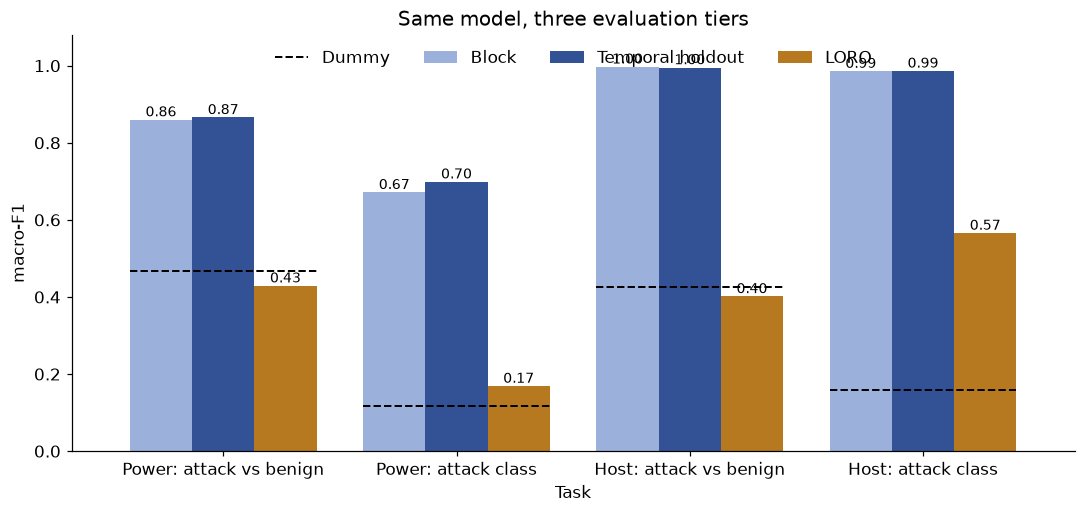

In [4]:
rows=[]
for name,base in [("Power: attack vs benign","power_binary"),("Power: attack class","power_group"),("Host: attack vs benign","host_binary"),("Host: attack class","host_group")]:
    rows.append([name, m(base), m(base+"_hyb"), m(base+"_LORO"), m(base,"Dummy (majority)")])
H = pd.DataFrame(rows, columns=["Task","Block","Temporal holdout","LORO","Dummy baseline"]).set_index("Task")
display(H.round(3).style.background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None))
ax = H[["Block","Temporal holdout","LORO"]].plot.bar(figsize=(10,4.8), color=[GREY,BLUE,ORANGE], width=0.8, rot=0)
for i,v in enumerate(H["Dummy baseline"]): ax.hlines(v, i-.4, i+.4, colors="black", linestyles="--", lw=1.3, label="Dummy" if i==0 else None)
ax.set_ylim(0,1.08); ax.set_ylabel("macro-F1"); ax.set_title("Same model, three evaluation tiers"); ax.legend(frameon=False, ncol=4, loc="upper center")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.tight_layout(); plt.show()

**Takeaway:** host data scores near-perfectly except under leave-one-recording-out; power separates attack from benign moderately but attack *class* poorly across recordings. Scores fall as the split gets stricter, which is why the strict tiers are the credible ones.

## 5. Model comparison (temporal-holdout tier)

task,model,accuracy,macro_F1,weighted_F1,train_s,infer_ms/row
power_binary,Dummy (majority),0.915600,0.478000,0.875200,0.030000,0.000000
power_binary,LogisticRegression,0.715300,0.567600,0.777700,0.250000,0.000200
power_binary,RandomForest,0.960100,0.865700,0.959300,2.870000,0.005900
power_group,Dummy (majority),0.302600,0.116100,0.140600,0.040000,0.000000
power_group,LogisticRegression,0.603900,0.591200,0.597600,1.330000,0.000400
power_group,RandomForest,0.683300,0.698800,0.680800,4.000000,0.012400
host_binary,Dummy (majority),0.809100,0.447200,0.723700,0.000000,0.000100
host_binary,LogisticRegression,0.361900,0.361700,0.354100,0.500000,0.010300
host_binary,RandomForest,0.997000,0.995100,0.997000,1.470000,0.041900
host_group,Dummy (majority),0.481200,0.162400,0.312700,0.000000,0.000100


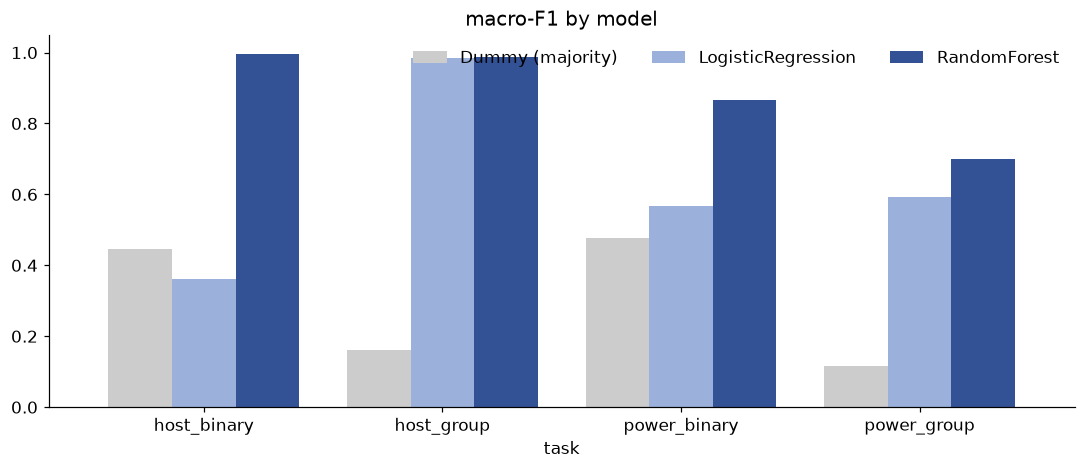

In [5]:
rows=[]
for exp in ["power_binary_hyb","power_group_hyb","host_binary_hyb","host_group_hyb"]:
    for mod in ["Dummy (majority)","LogisticRegression","RandomForest"]:
        r=M.loc[(exp,mod)]; rows.append([exp.replace("_hyb",""),mod,r.accuracy,r.macro_F1,r.weighted_F1,r.train_s,r.infer_ms_per_row])
T=pd.DataFrame(rows,columns=["task","model","accuracy","macro_F1","weighted_F1","train_s","infer_ms/row"])
display(T.round(4).style.hide(axis="index").background_gradient(subset=["macro_F1"],cmap="Blues",vmin=0,vmax=1))
P=T.pivot(index="task",columns="model",values="macro_F1")[["Dummy (majority)","LogisticRegression","RandomForest"]]
P.plot.bar(figsize=(10,4.4),color=["#CCCCCC",GREY,BLUE],rot=0,width=.8).set_title("macro-F1 by model"); plt.ylim(0,1.05); plt.legend(frameon=False,ncol=3); plt.tight_layout(); plt.show()

## 6. Confusion matrices (temporal holdout, Random Forest)

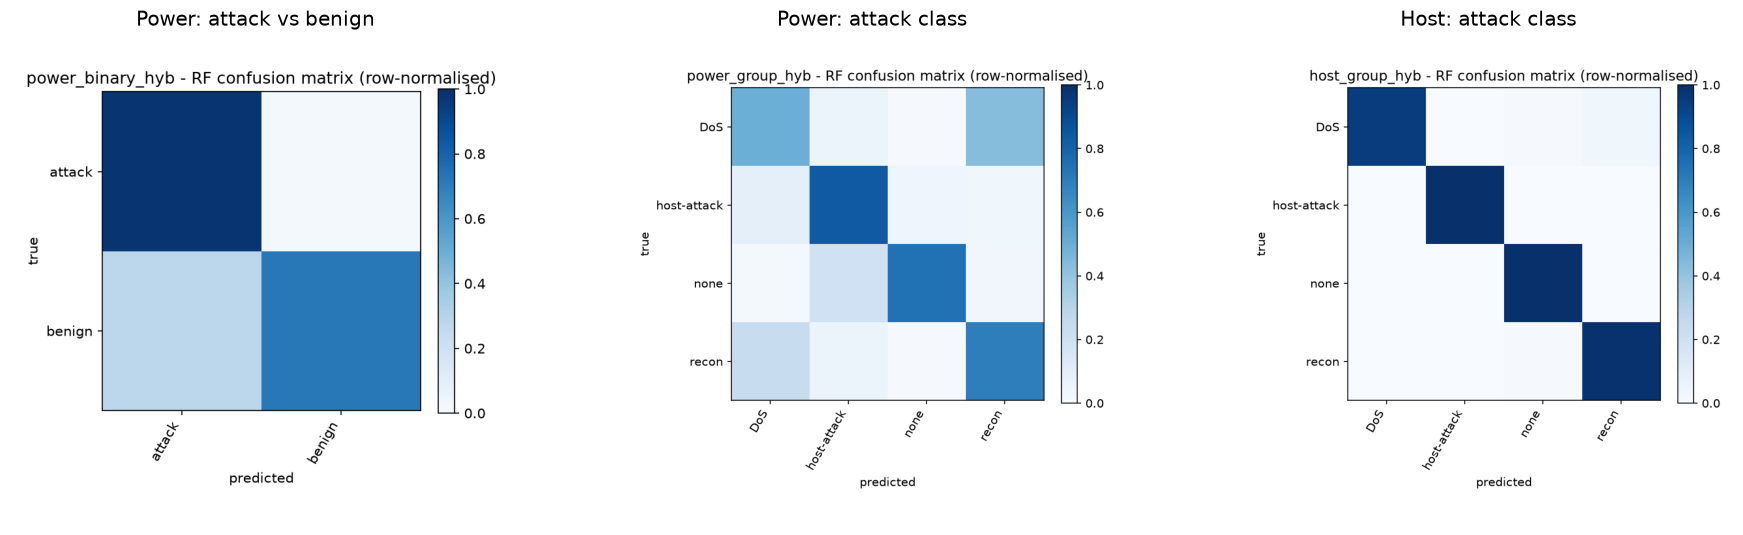

,precision,recall,f1-score,support
"Power binary, per class",,,,
attack,0.974,0.982,0.978,46728.0
benign,0.789,0.720,0.753,4310.0


,precision,recall,f1-score,support
"Host class, per class",,,,
DoS,1.000,0.951,0.975,285.0
host-attack,1.000,0.999,1.000,1231.0
none,0.989,0.999,0.994,692.0
recon,0.966,0.989,0.977,350.0


In [6]:
pairs=[("power_binary_hyb","Power: attack vs benign"),("power_group_hyb","Power: attack class"),("host_group_hyb","Host: attack class")]
fig,axs=plt.subplots(1,3,figsize=(17,5))
for a,(k,t) in zip(axs,pairs): a.imshow(mpimg.imread(R/f"{k}_RF_confusion.png")); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
display(pd.read_csv(R/"power_binary_hyb_RF_per_class.csv",index_col=0).round(3).head(2).rename_axis("Power binary, per class"))
display(pd.read_csv(R/"host_group_hyb_RF_per_class.csv",index_col=0).round(3).iloc[:-3].rename_axis("Host class, per class"))

## 7. Does it generalise to a recording it never saw? (LORO)

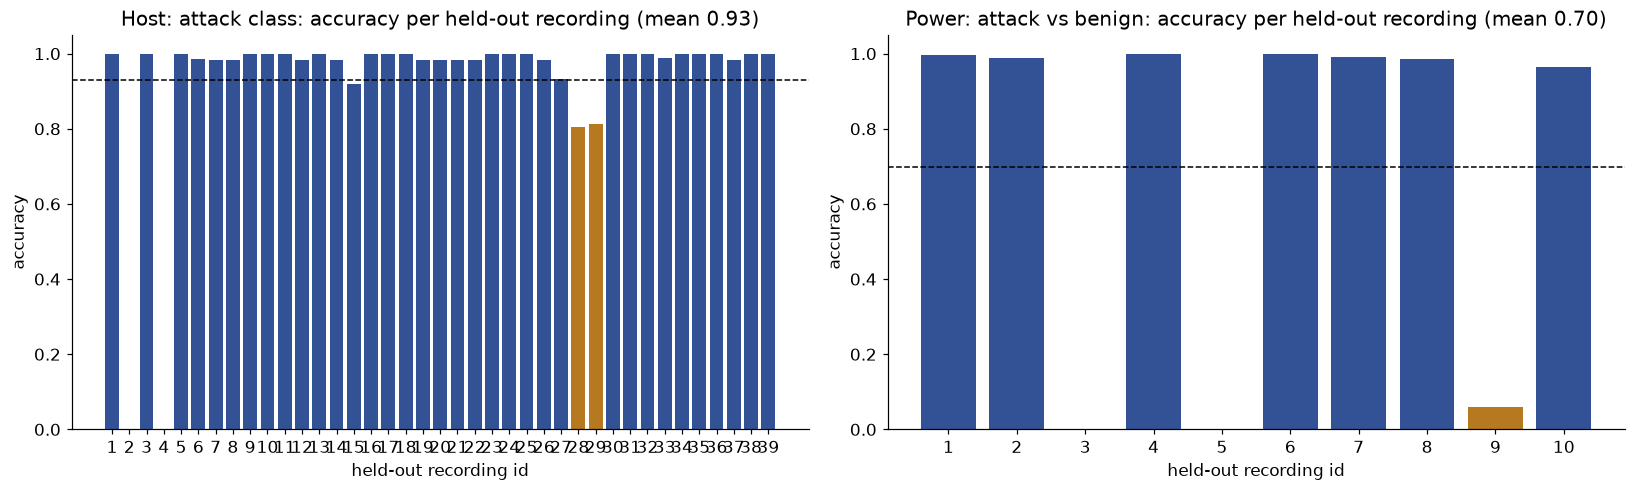

Host recordings with accuracy < 0.9:


,rec_id,true,rows,acc,note
1,2,none,1151,0.0000,NaN
3,4,none,1151,0.0000,NaN
27,28,DoS,61,0.8033,NaN
28,29,DoS,59,0.8136,NaN


In [7]:
fig,axs=plt.subplots(1,2,figsize=(15,4.6))
for a,k,t in zip(axs,["host_group","power_binary"],["Host: attack class","Power: attack vs benign"]):
    d=pd.read_csv(R/f"{k}_LORO_per_recording.csv"); cols=[BLUE if x>=.9 else ORANGE for x in d.acc]
    a.bar(d.rec_id.astype(str),d.acc,color=cols); a.axhline(d.acc.mean(),ls="--",c="k",lw=1); a.set_ylim(0,1.05)
    a.set_title(f"{t}: accuracy per held-out recording (mean {d.acc.mean():.2f})"); a.set_xlabel("held-out recording id"); a.set_ylabel("accuracy")
plt.tight_layout(); plt.show()
d=pd.read_csv(R/"host_group_LORO_per_recording.csv"); print("Host recordings with accuracy < 0.9:"); display(d[d.acc<0.9])

**Takeaway:** host attack recordings are recognised almost every time when unseen; failures are concentrated in **benign** recordings (the model has few benign states to learn from).

## 8. Network flows: what is and is not learnable

device,task,RF macro-F1,Dummy
netA,DoS vs recon (family),0.960000,0.312000
netA,"Specific attack type, block",0.541000,0.022000
netA,"Specific attack type, whole recordings",0.256000,0.024000
netA,"Specific attack type, LORO",0.240000,nan
netB,DoS vs recon (family),1.000000,0.394000
netB,"Specific attack type, block",0.546000,0.022000
netB,"Specific attack type, whole recordings",0.286000,0.013000
netB,"Specific attack type, LORO",0.273000,nan


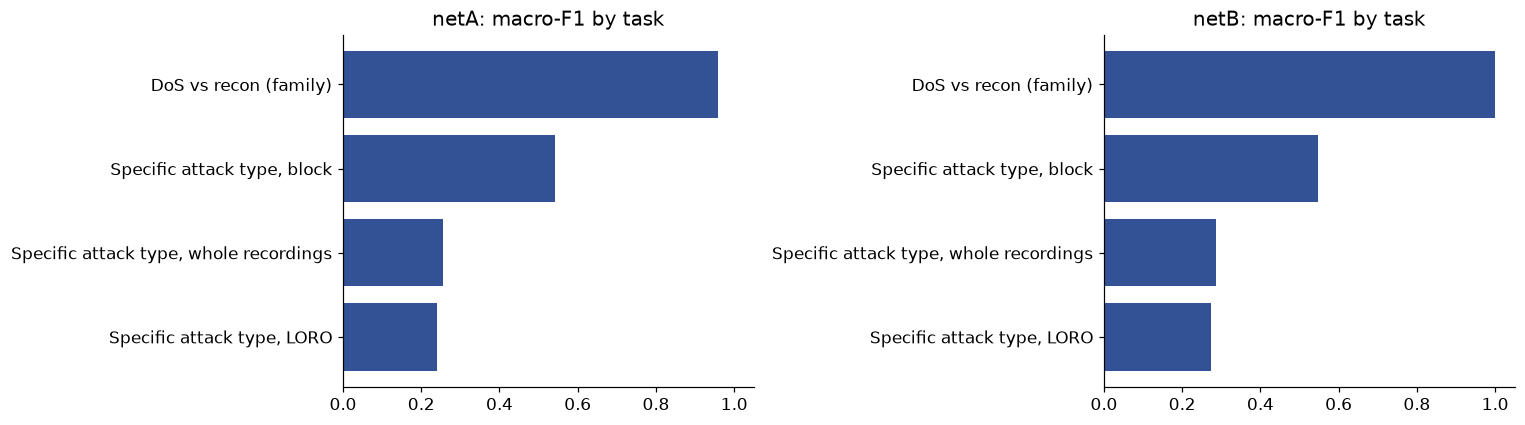

In [8]:
rows=[]
for dev in ["netA","netB"]:
    rows.append([dev,"DoS vs recon (family)",m(f"{dev}_group_noport"),m(f"{dev}_group_noport","Dummy (majority)")])
    rows.append([dev,"Specific attack type, block",m(f"{dev}_attack_type"),m(f"{dev}_attack_type","Dummy (majority)")])
    rows.append([dev,"Specific attack type, whole recordings",m(f"{dev}_attack_type_rec"),m(f"{dev}_attack_type_rec","Dummy (majority)")])
    rows.append([dev,"Specific attack type, LORO",m(f"{dev}_attack_type_LORO"),np.nan])
N=pd.DataFrame(rows,columns=["device","task","RF macro-F1","Dummy"]); display(N.round(3).style.hide(axis="index"))
fig,axs=plt.subplots(1,2,figsize=(14,4)); 
for a,dev in zip(axs,["netA","netB"]):
    s=N[N.device==dev]; a.barh(s.task[::-1],s["RF macro-F1"][::-1],color=BLUE); a.set_xlim(0,1.05); a.set_title(f"{dev}: macro-F1 by task")
plt.tight_layout(); plt.show()

### Leave-one-attack-type-out: is the high DoS-vs-recon score overfitting?
Each attack type is removed from training entirely, then the model must place it into DoS or recon.

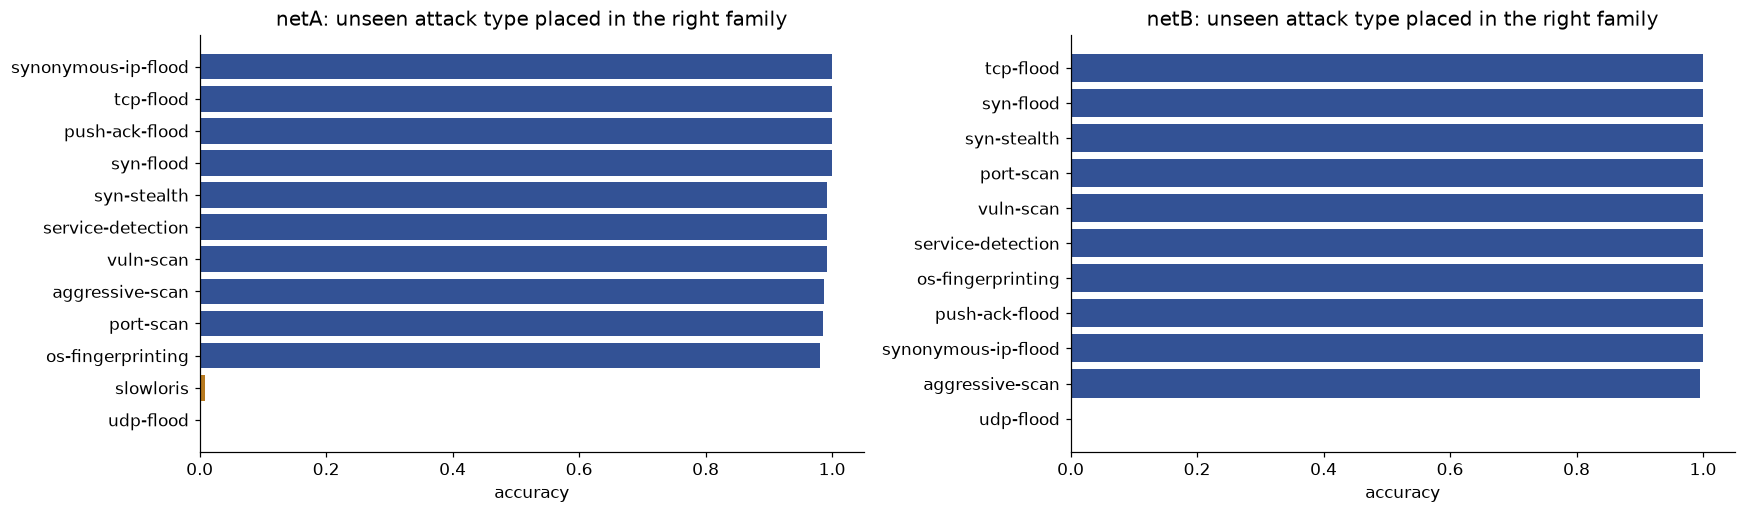

Unseen types correct (>=0.9): netA 10/12, netB 10/11


In [9]:
fig,axs=plt.subplots(1,2,figsize=(16,4.8),sharex=False)
for a,dev in zip(axs,["netA","netB"]):
    d=pd.read_csv(R/f"{dev}_leave_one_attack_out.csv").sort_values("acc")
    a.barh(d.held_out_attack,d.acc,color=[ORANGE if x<.5 else BLUE for x in d.acc]); a.set_xlim(0,1.05)
    a.set_title(f"{dev}: unseen attack type placed in the right family"); a.set_xlabel("accuracy")
plt.tight_layout(); plt.show()
a=pd.read_csv(R/"netA_leave_one_attack_out.csv"); b=pd.read_csv(R/"netB_leave_one_attack_out.csv")
print(f"Unseen types correct (>=0.9): netA {int((a.acc>=.9).sum())}/{len(a)}, netB {int((b.acc>=.9).sum())}/{len(b)}")

**Takeaway:** the network model separates DoS from recon and generalises to unseen scans and TCP-style floods. It **fails on unseen UDP flood and slowloris**, so it is a family-level detector, not a sub-type identifier.

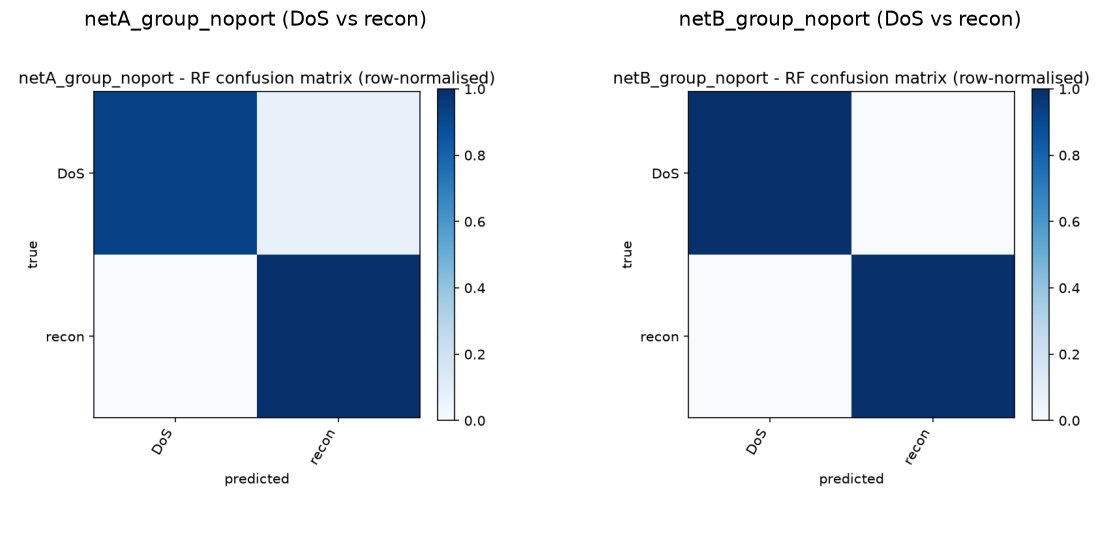

In [10]:
fig,axs=plt.subplots(1,2,figsize=(11,5))
for a,k in zip(axs,["netA_group_noport","netB_group_noport"]): a.imshow(mpimg.imread(R/f"{k}_RF_confusion.png")); a.set_title(k+" (DoS vs recon)"); a.axis("off")
plt.tight_layout(); plt.show()

### Network detail: which attacks are recognised, and which are confused?

In [11]:
f=pd.read_csv(R/"file_inventory.csv"); f=f[f.device.str.contains("network")].copy()
f["attack"]=f.file.str.replace(r"^EVSE-[AB]-(charging|idle)-","",regex=True,case=False).str.replace(".csv","",regex=False).str.lower().str.replace("evse-b-maliciousev-","",regex=False)
f["attack"]=f["attack"].replace({"portscan":"port-scan","service-detection-scan":"service-detection","slowloris-scan":"slowloris","syn-stealth-scan":"syn-stealth","synonymous-ip":"synonymous-ip-flood","vulnerability-scan":"vuln-scan"})
tab=f.pivot_table(index="attack",columns="device",values="rows",aggfunc="sum").fillna(0).astype(int)
tab["family"]=["DoS" if any(k in a for k in ["flood","slowloris","fragmentation"]) else ("benign" if "benign" in a else "recon") for a in tab.index]
display(tab.sort_values(["family","attack"]).style.format({"EVSE-A network":"{:,}","EVSE-B network":"{:,}"}))
print("Flows per attack type in the original files. Types with only a handful of flows (e.g. icmp-flood) cannot be modelled.")

device,EVSE-A network,EVSE-B network,family
attack,,,
icmp-flood,2,60,DoS
icmp-fragmentation,16,12,DoS
push-ack-flood,"65,536","131,118",DoS
slowloris,"4,201",0,DoS
syn-flood,"131,107","131,089",DoS
synonymous-ip-flood,"131,093","131,092",DoS
tcp-flood,"131,087","131,107",DoS
udp-flood,"15,956","16,519",DoS
benign,82,0,benign


Flows per attack type in the original files. Types with only a handful of flows (e.g. icmp-flood) cannot be modelled.


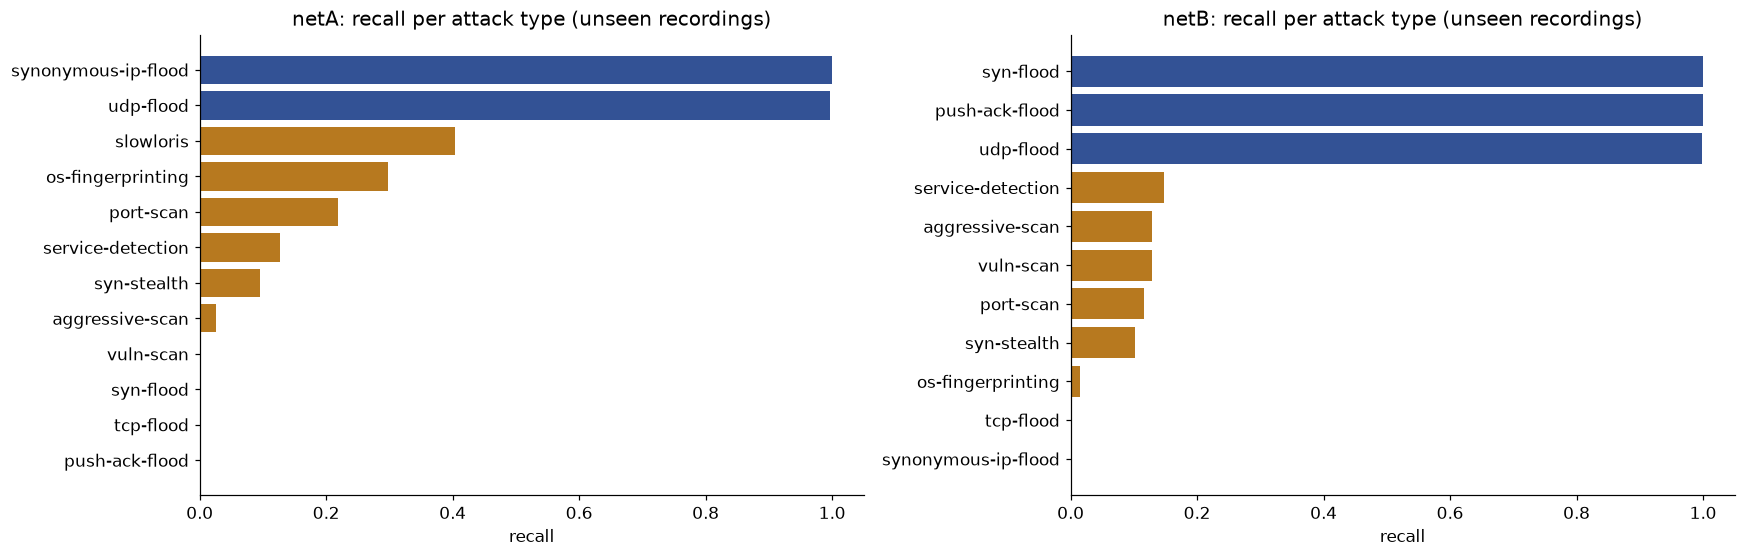

In [12]:
fig,axs=plt.subplots(1,2,figsize=(16,5.2))
for a,dev in zip(axs,["netA","netB"]):
    d=pd.read_csv(R/f"{dev}_attack_type_rec_RF_per_class.csv",index_col=0).iloc[:-3]["recall"].sort_values()
    a.barh(d.index,d.values,color=[ORANGE if v<.5 else BLUE for v in d.values]); a.set_xlim(0,1.05)
    a.set_title(f"{dev}: recall per attack type (unseen recordings)"); a.set_xlabel("recall")
plt.tight_layout(); plt.show()

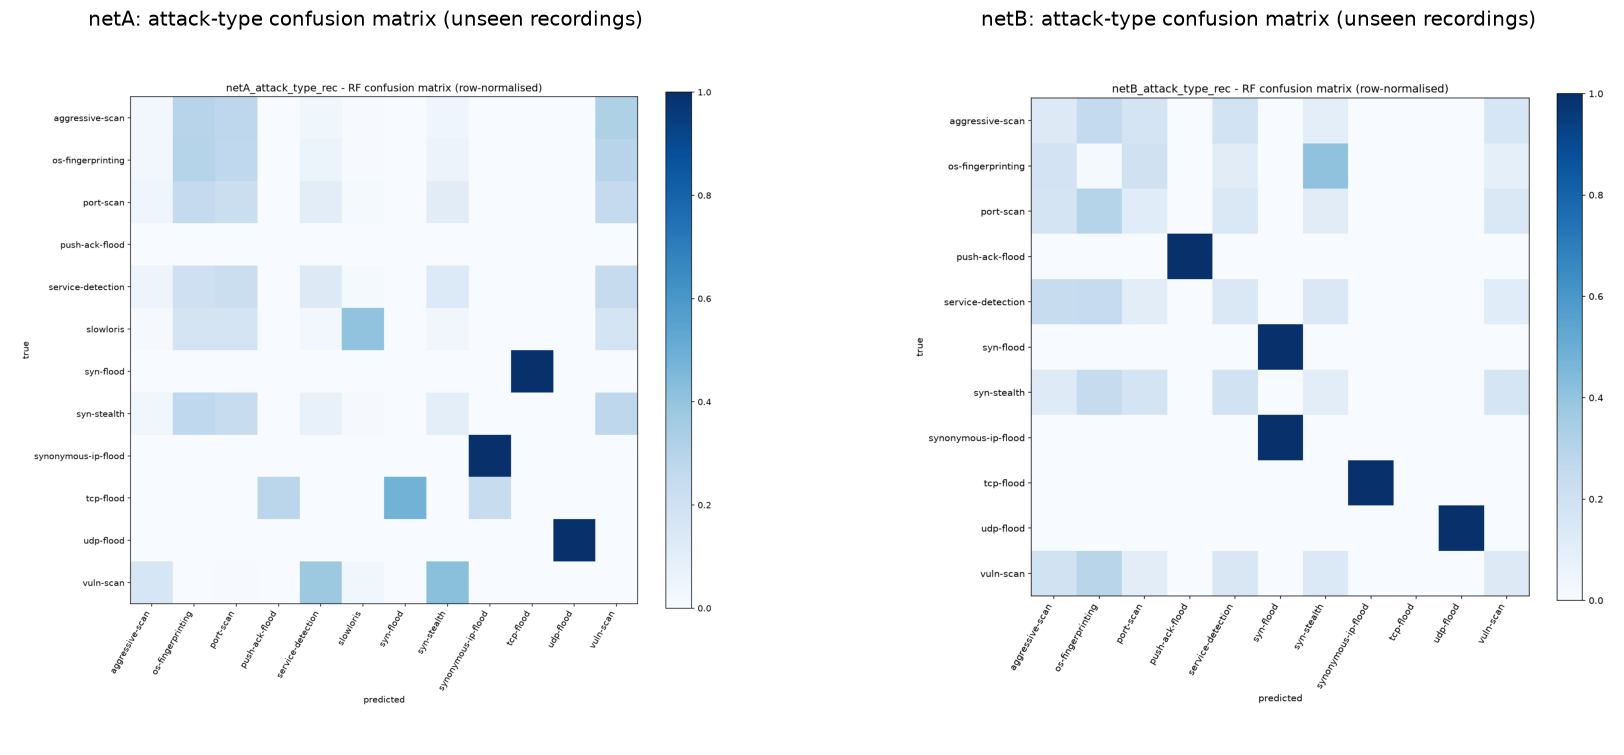

In [13]:
fig,axs=plt.subplots(1,2,figsize=(17,7))
for a,dev in zip(axs,["netA","netB"]): a.imshow(mpimg.imread(R/f"{dev}_attack_type_rec_RF_confusion.png")); a.set_title(f"{dev}: attack-type confusion matrix (unseen recordings)"); a.axis("off")
plt.tight_layout(); plt.show()

**Takeaway:** floods that look different from scans (push-ack-flood, udp-flood) are recognised, but the scan types (port-scan, aggressive-scan, service-detection, os-fingerprinting, vuln-scan) are mixed up with each other. Within a family the traffic looks alike, so the model works at **family level (DoS vs recon)**, which is what the next charts show.

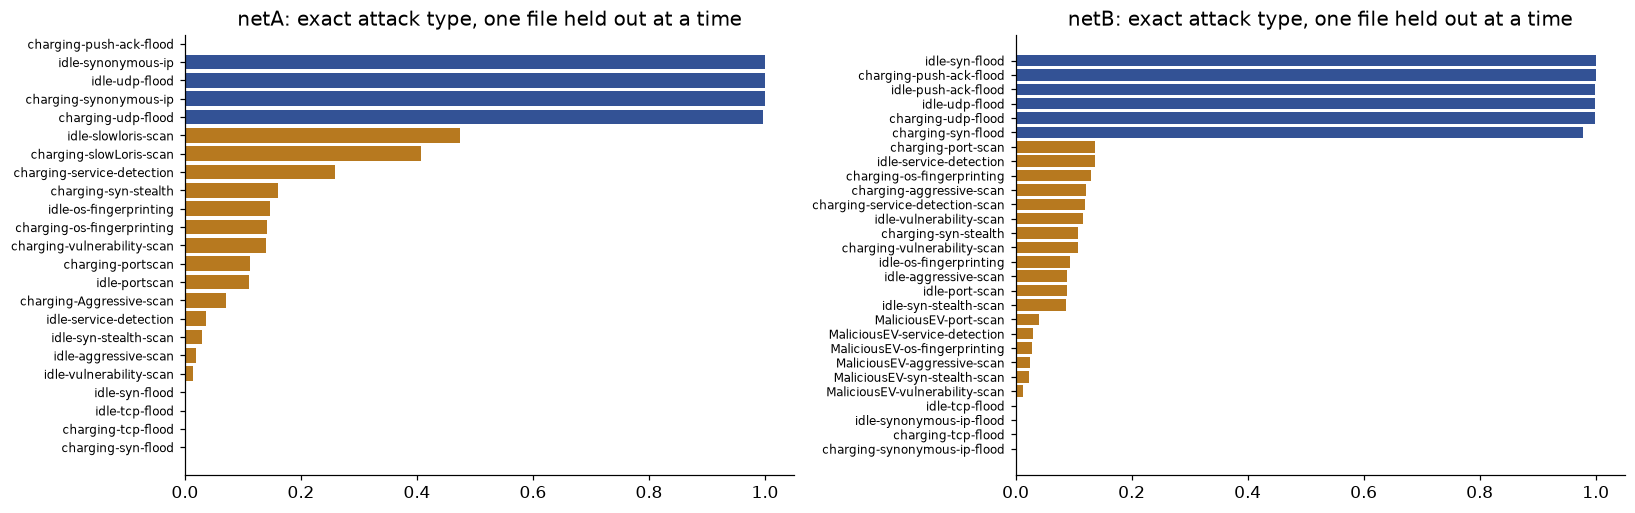

In [14]:
fig,axs=plt.subplots(1,2,figsize=(15,4.8))
for a,dev in zip(axs,["netA","netB"]):
    d=pd.read_csv(R/f"{dev}_attack_type_LORO_per_recording.csv").sort_values("acc")
    d["name"]=d.rec_id.str.replace(r"\.csv","",regex=True).str.replace(r"^EVSE-[AB]-","",regex=True)
    a.barh(d.name,d.acc,color=[ORANGE if v<.5 else BLUE for v in d.acc]); a.set_xlim(0,1.05); a.set_title(f"{dev}: exact attack type, one file held out at a time"); a.tick_params(axis="y",labelsize=8)
plt.tight_layout(); plt.show()

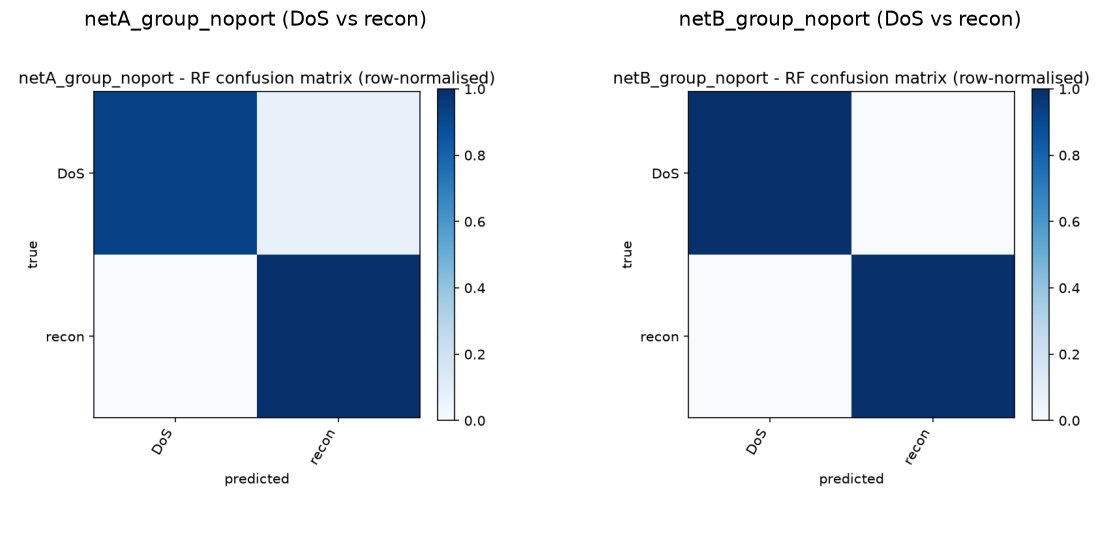

,precision,recall,f1-score,support
"netA DoS vs recon, whole-file holdout",,,,
DoS,0.992,0.923,0.956,18235.0
recon,0.907,0.990,0.947,13799.0


,precision,recall,f1-score,support
"netB DoS vs recon, whole-file holdout",,,,
DoS,1.0,1.0,1.0,12000.0
recon,1.0,1.0,1.0,32000.0


In [15]:
fig,axs=plt.subplots(1,2,figsize=(11,5))
for a,k in zip(axs,["netA_group_noport","netB_group_noport"]): a.imshow(mpimg.imread(R/f"{k}_RF_confusion.png")); a.set_title(k+" (DoS vs recon)"); a.axis("off")
plt.tight_layout(); plt.show()
for dev in ["netA","netB"]:
    display(pd.read_csv(R/f"{dev}_group_rec_RF_per_class.csv",index_col=0).round(3).iloc[:2].rename_axis(f"{dev} DoS vs recon, whole-file holdout"))

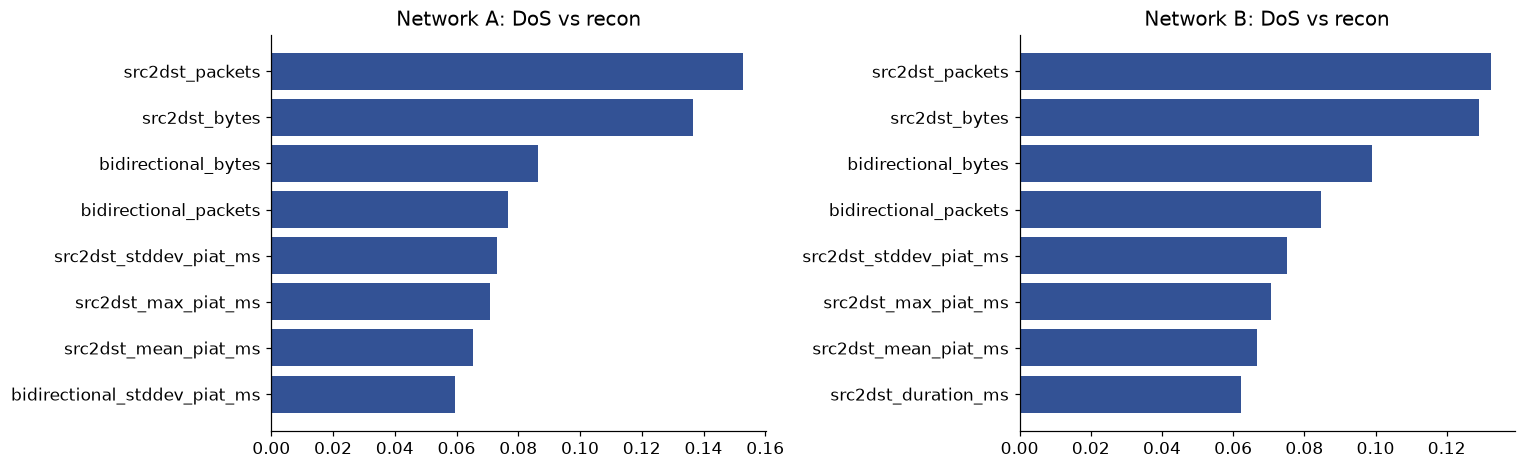

In [16]:
fig,axs=plt.subplots(1,2,figsize=(14,4.4))
for a,k,t in [(axs[0],"netA_group_noport","Network A: DoS vs recon"),(axs[1],"netB_group_noport","Network B: DoS vs recon")]:
    d=pd.read_csv(R/f"{k}_RF_importance.csv",index_col=0).iloc[:,0].sort_values().tail(8); a.barh(d.index,d.values,color=BLUE); a.set_title(t)
plt.tight_layout(); plt.show()

## 9. Anomaly detection (Isolation Forest trained on benign power only)

In [17]:
r=M.loc[("power_anomaly","IsolationForest(benign-only)")]
display(pd.DataFrame({"ROC-AUC":[r.ROC_AUC],"PR-AUC":[r.PR_AUC],"precision":[r.precision],"recall":[r.recall]}).round(3).style.hide(axis="index"))

ROC-AUC,PR-AUC,precision,recall
0.706000,0.946000,0.970000,0.359000


An anomaly score is not proof of an attack: precision is high but recall is low, so it is useful as a supporting signal, not a detector on its own.

## 10. What the models rely on (top features)

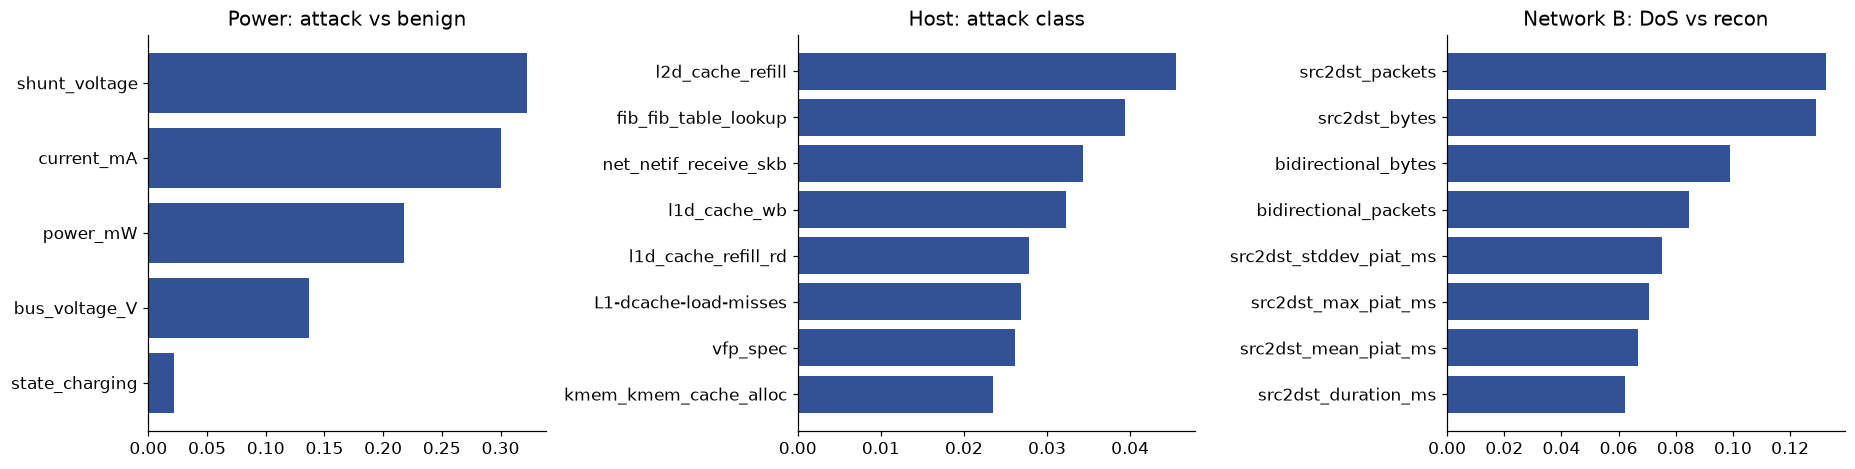

In [18]:
fig,axs=plt.subplots(1,3,figsize=(17,4.4))
for a,k,t in [(axs[0],"power_binary_hyb","Power: attack vs benign"),(axs[1],"host_group_hyb","Host: attack class"),(axs[2],"netB_group_noport","Network B: DoS vs recon")]:
    d=pd.read_csv(R/f"{k}_RF_importance.csv",index_col=0).iloc[:,0].sort_values().tail(8); a.barh(d.index,d.values,color=BLUE); a.set_title(t)
plt.tight_layout(); plt.show()